# Abbildung, Auflösung und Aberrationen

Dieses Notebook verbindet `pyoptics.imaging` (kohärente Abbildung durch ein
4f-System mit der numerischen Apertur NA), `pyoptics.bases` (Fringe-Zernike-Polynome
für Wellenfrontfehler) und `pyoptics.propagators` (dreidimensionale
Punktbildfunktion). Themen: Zernike-Galerie, Punktbildfunktion (PSF) mit
Aberrationen, Strehl-Verhältnis und Maréchal-Näherung, Zernike-Fit,
kohärente und inkohärente Abbildung, Rayleigh-Kriterium und der Fokus in 3D.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from pyoptics import imaging
from pyoptics import propagators as prop
from pyoptics.bases import FringeZernikes, fringe_to_n_m
from pyoptics.fft import FT, inv_FT
from pyoptics.masks import circular_mask
from pyoptics.utils import grid2d, freq_grid, wavenumber

plt.rcParams.update({"figure.dpi": 100, "image.origin": "lower", "font.size": 11})

## 1. Fringe-Zernike-Polynome

Zernike-Polynome $Z_j(\rho, \varphi)$ sind auf dem Einheitskreis orthogonal und
beschreiben die typischen Bildfehler rotationssymmetrischer Systeme. `FringeZernikes`
nummeriert sie in der Fringe-Reihenfolge (Index ab 1) und normiert sie auf
$|Z_j(\rho = 1)| = 1$.

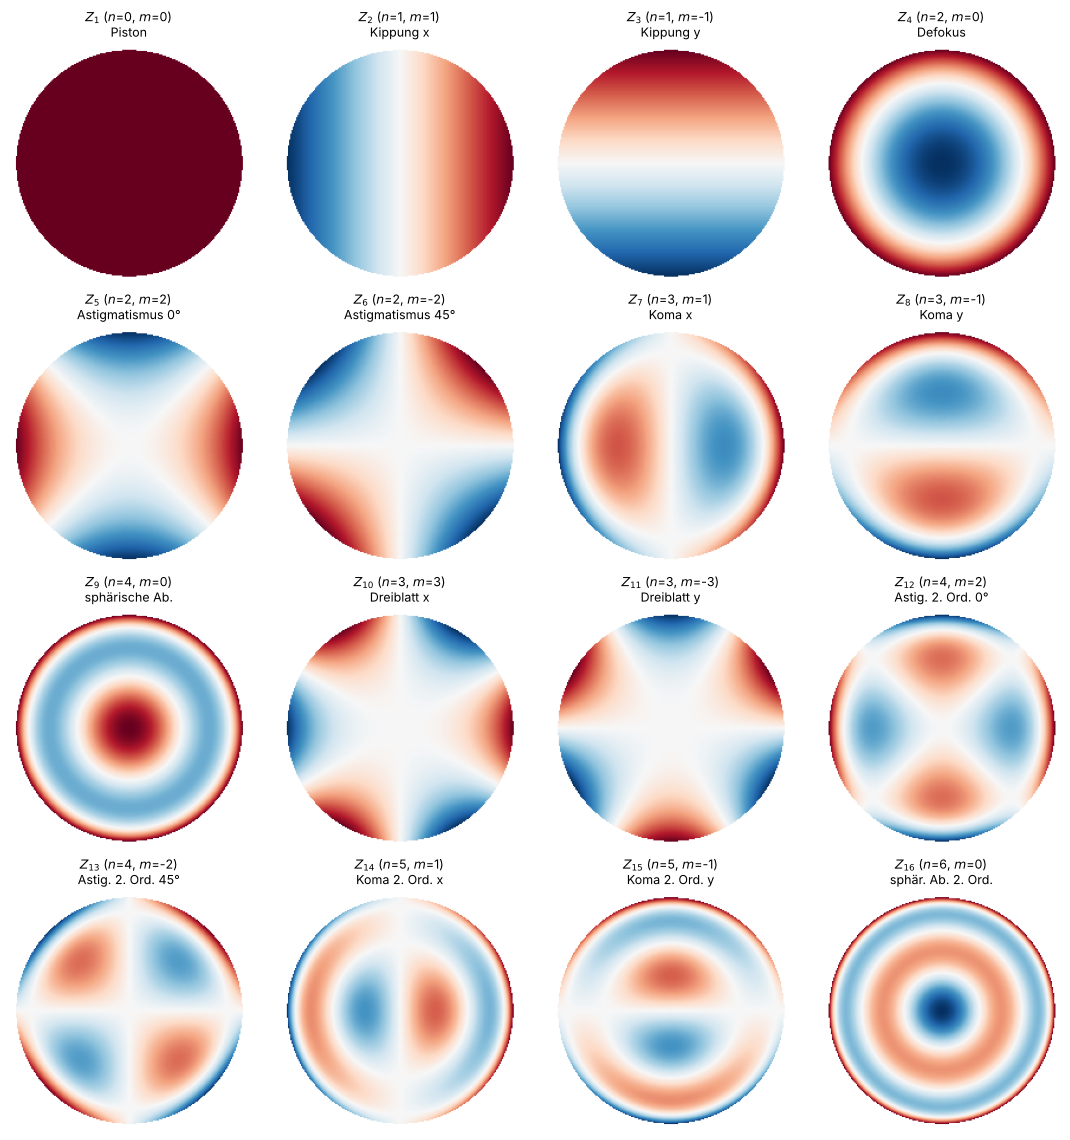

In [2]:
names = {1: "Piston", 2: "Kippung x", 3: "Kippung y", 4: "Defokus", 5: "Astigmatismus 0°",
         6: "Astigmatismus 45°", 7: "Koma x", 8: "Koma y", 9: "sphärische Ab.", 10: "Dreiblatt x",
         11: "Dreiblatt y", 12: "Astig. 2. Ord. 0°", 13: "Astig. 2. Ord. 45°", 14: "Koma 2. Ord. x",
         15: "Koma 2. Ord. y", 16: "sphär. Ab. 2. Ord."}
xp, yp, _, _ = grid2d(-1.05, 1.05, -1.05, 1.05, 201)
Zb = FringeZernikes(xp, yp)
mask_p = circular_mask(xp, yp, 1.0).astype(bool)

fig, axes = plt.subplots(4, 4, figsize=(11, 11.5))
for ax, j in zip(axes.flat, range(1, 17)):
    Zj = np.where(mask_p, Zb([j], [1.0]), np.nan)
    ax.imshow(Zj, cmap="RdBu_r", vmin=-1, vmax=1, extent=(xp[0], xp[-1], yp[0], yp[-1]))
    n, m = fringe_to_n_m(j)
    ax.set_title(f"$Z_{{{j}}}$ ($n$={n}, $m$={m})\n{names[j]}", fontsize=9)
    ax.axis("off")
fig.tight_layout()

## 2. Punktbildfunktion mit Aberrationen

Die Pupillenfunktion ist $P(\rho, \varphi) = \mathrm{circ}(\rho)\, e^{2\pi i W(\rho,\varphi)}$ mit
dem Wellenfrontfehler $W = \sum_j c_j Z_j$ in Wellenlängen. Die PSF ist das
Betragsquadrat ihrer Fourier-Transformierten. Mit Zero-Padding um den Faktor 8
um die Pupille wird die PSF fein genug abgetastet; die Bildkoordinaten sind in
Einheiten von $\lambda/\mathrm{NA}$ angegeben.

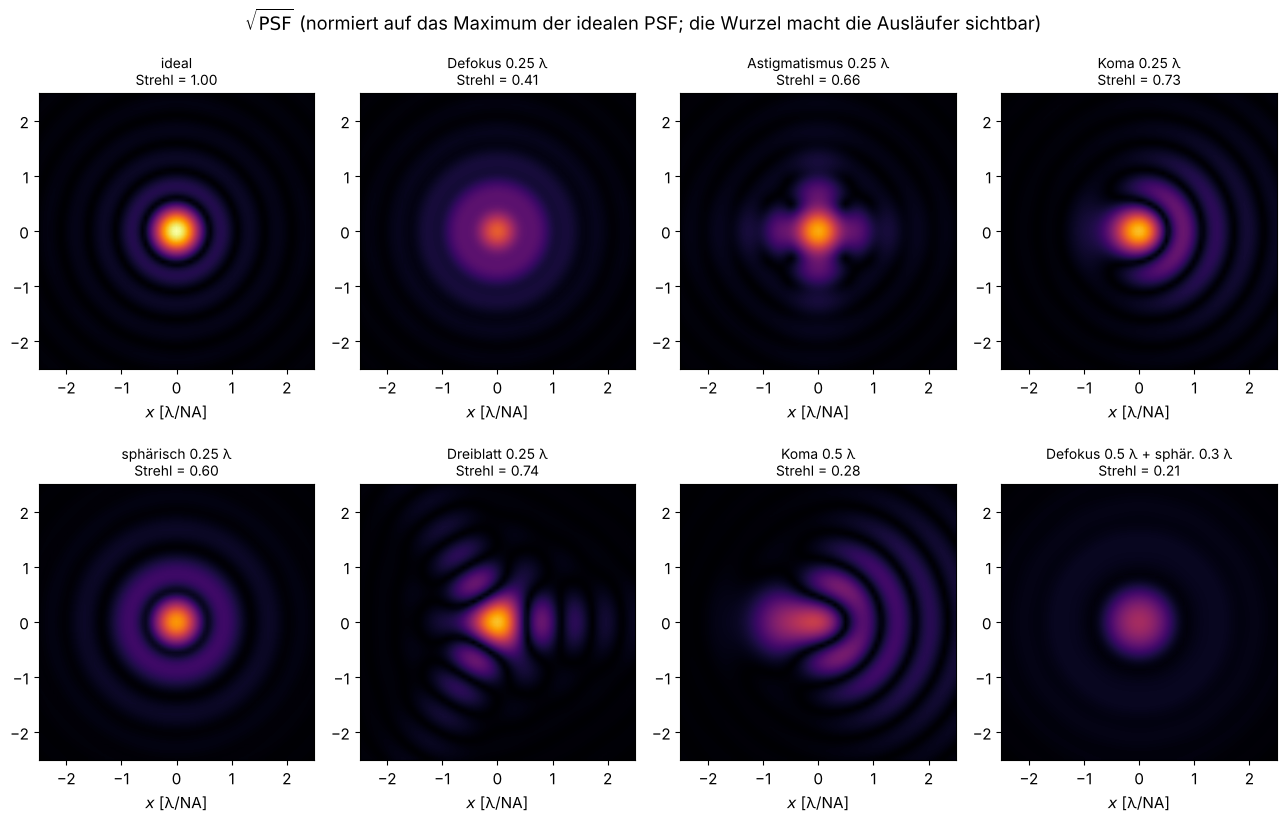

In [3]:
Lp, Np = 16.0, 1024           # Pupillenkoordinaten in Einheiten des Pupillenradius
xq, yq, _, _ = grid2d(-Lp/2, Lp/2, -Lp/2, Lp/2, Np)
Zq = FringeZernikes(xq, yq)
pupil = circular_mask(xq, yq, 1.0).astype(float)
u = np.fft.fftshift(np.fft.fftfreq(Np, xq[1] - xq[0]))  # Bildkoordinate in lambda/NA

def psf(coeffs):
    """coeffs: dict {Fringe-Index: Koeffizient in Wellen}"""
    W = sum(c*Zq([j], [1.0]) for j, c in coeffs.items()) if coeffs else 0.0
    P = pupil*np.exp(2j*np.pi*W)
    return np.abs(FT(P))**2

I_perfect = psf({})
I0 = I_perfect.max()

cases = [({}, "ideal"), ({4: 0.25}, "Defokus 0.25 λ"), ({5: 0.25}, "Astigmatismus 0.25 λ"),
         ({7: 0.25}, "Koma 0.25 λ"), ({9: 0.25}, "sphärisch 0.25 λ"), ({10: 0.25}, "Dreiblatt 0.25 λ"),
         ({7: 0.5}, "Koma 0.5 λ"), ({4: 0.5, 9: 0.3}, "Defokus 0.5 λ + sphär. 0.3 λ")]
c = 2.5
sel = np.abs(u) <= c
fig, axes = plt.subplots(2, 4, figsize=(13, 8.4))
for ax, (coeffs, title) in zip(axes.flat, cases):
    I = psf(coeffs)
    ax.imshow(np.sqrt(I[np.ix_(sel, sel)]/I0), extent=(-c, c, -c, c), cmap="inferno", vmax=1.0, interpolation="bilinear")
    ax.set_title(f"{title}\nStrehl = {I.max()/I0:.2f}", fontsize=10)
    ax.set_xlabel("$x$ [λ/NA]")
fig.suptitle("$\\sqrt{\\mathrm{PSF}}$ (normiert auf das Maximum der idealen PSF; die Wurzel macht die Ausläufer sichtbar)")
fig.tight_layout()

### Strehl-Verhältnis und Maréchal-Näherung

Das **Strehl-Verhältnis** ist die Spitzenintensität relativ zur idealen PSF.
Für kleine Fehler hängt es nur vom RMS-Wellenfrontfehler $\sigma$ ab, nicht von der
Art der Aberration:

$$S \approx \exp\big(-(2\pi\sigma)^2\big).$$

Als "beugungsbegrenzt" gilt ein System mit $S \geq 0.8$, also
$\sigma \lesssim \lambda/14$ (Maréchal-Kriterium). Hinweis: Bei Kippung (Tilt)
verschiebt sich die PSF nur, deshalb wird hier das Maximum der PSF genommen und nicht
der Wert im Ursprung.

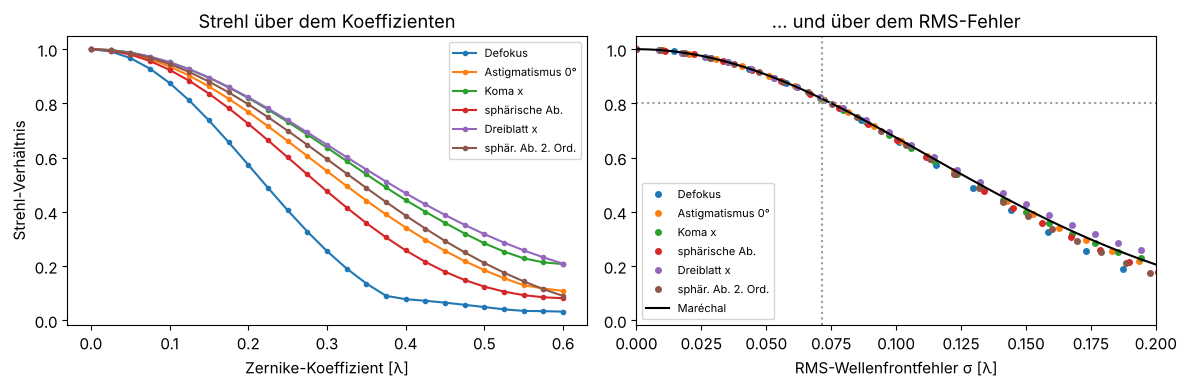

In [4]:
amps = np.linspace(0, 0.6, 25)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for j in (4, 5, 7, 9, 10, 16):
    rms, strehl = [], []
    Zj = Zq([j], [1.0])
    for a in amps:
        rms.append(np.std(a*Zj[pupil > 0]))
        strehl.append(psf({j: a}).max()/I0)
    axes[0].plot(amps, strehl, "o-", ms=3, label=names[j])
    axes[1].plot(rms, strehl, "o", ms=4, label=names[j])
s = np.linspace(0, 0.2, 100)
axes[1].plot(s, np.exp(-(2*np.pi*s)**2), "k-", lw=1.5, label="Maréchal")
axes[1].axhline(0.8, color="0.6", ls=":"); axes[1].axvline(1/14, color="0.6", ls=":")
axes[0].set_xlabel("Zernike-Koeffizient [λ]"); axes[0].set_ylabel("Strehl-Verhältnis")
axes[1].set_xlabel("RMS-Wellenfrontfehler σ [λ]"); axes[1].set_xlim(0, 0.2)
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
axes[0].set_title("Strehl über dem Koeffizienten"); axes[1].set_title("... und über dem RMS-Fehler")
fig.tight_layout()

## 3. Zernike-Fit einer gemessenen Wellenfront

`coeffs_from_field()` zerlegt eine Wellenfront (hier: synthetisch mit
Rauschen) per Least-Squares in Zernike-Polynome. Aus den Koeffizienten lassen
sich die Bildfehler direkt ablesen.

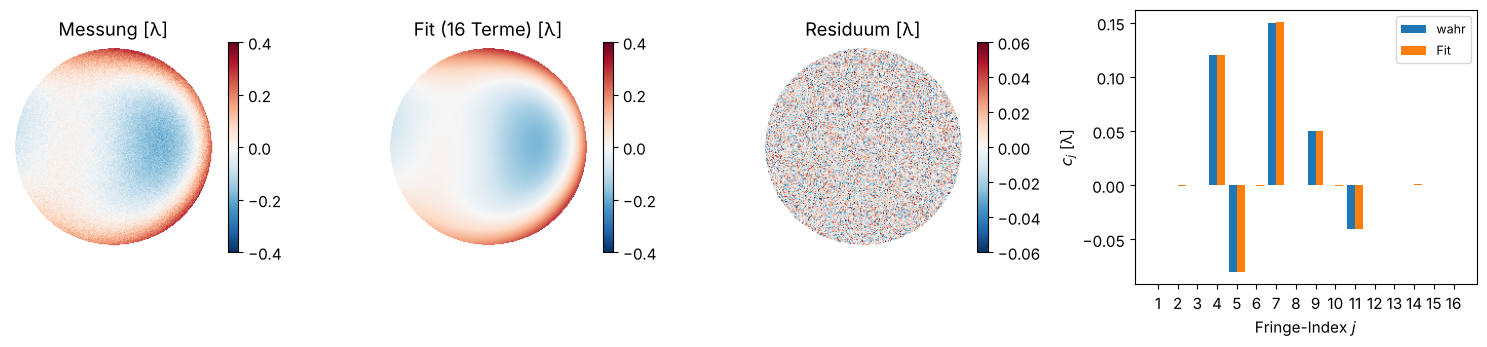

In [5]:
rng = np.random.default_rng(0)
true = {4: 0.12, 5: -0.08, 7: 0.15, 9: 0.05, 11: -0.04}
indices = list(range(1, 17))
W_true = sum(c*Zb([j], [1.0]) for j, c in true.items())
W_meas = W_true + 0.02*rng.standard_normal(W_true.shape)
W_meas_masked = np.where(mask_p, W_meas, 0.0)
coeffs_fit = Zb.coeffs_from_field(W_meas_masked, indices)
W_fit = Zb(indices, coeffs_fit)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), gridspec_kw={"width_ratios": [1, 1, 1, 1.5]})
for ax, W, title in zip(axes, (W_meas, W_fit, W_meas - W_fit), ("Messung [λ]", "Fit (16 Terme) [λ]", "Residuum [λ]")):
    im = ax.imshow(np.where(mask_p, W, np.nan), cmap="RdBu_r", extent=(xp[0], xp[-1], yp[0], yp[-1]),
                   vmin=-0.4 if title != "Residuum [λ]" else -0.06, vmax=0.4 if title != "Residuum [λ]" else 0.06)
    fig.colorbar(im, ax=ax, fraction=0.046); ax.set_title(title); ax.axis("off")
axes[3].bar(np.array(indices) - 0.2, [true.get(j, 0.0) for j in indices], 0.4, label="wahr")
axes[3].bar(np.array(indices) + 0.2, np.real(coeffs_fit), 0.4, label="Fit")
axes[3].set_xticks(indices); axes[3].set_xlabel("Fringe-Index $j$"); axes[3].set_ylabel("$c_j$ [λ]")
axes[3].legend(fontsize=9)
fig.tight_layout()

## 4. Kohärente und inkohärente Abbildung

`imaging.image()` bildet ein (komplexes) Objekt kohärent ab: Das Spektrum wird
bei $|k_\perp| > k\,\mathrm{NA}$ abgeschnitten. Die kohärente Transferfunktion (CTF)
ist also die Pupille selbst, mit Grenzfrequenz $\mathrm{NA}/\lambda$.

Bei inkohärenter Beleuchtung (z.B. Fluoreszenz) addieren sich die Intensitäten.
Das Bild ist die Objektintensität gefaltet mit $|h|^2$, der Intensitäts-PSF
(aus `imaging.get_psf()`). Die optische Transferfunktion (OTF) ist die
Autokorrelation der Pupille und reicht doppelt so weit, bis $2\mathrm{NA}/\lambda$,
fällt aber zu hohen Frequenzen hin ab.

Ein Siemensstern zeigt beide Grenzen direkt: Die Speichen verschwimmen zur
Mitte hin dort, wo ihre Periode unter die Auflösungsgrenze fällt.

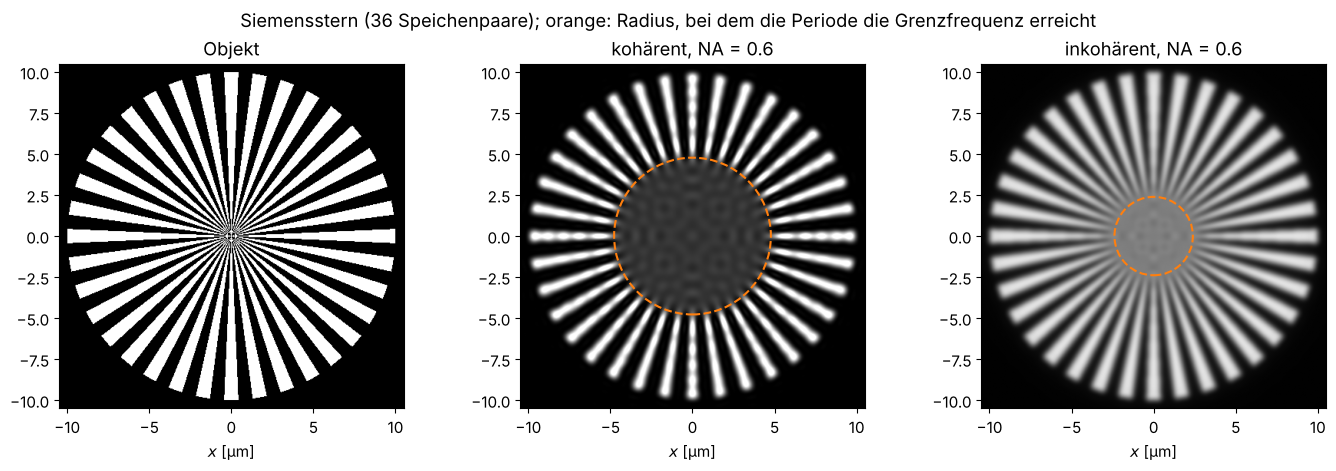

In [6]:
wl, NA = 0.5, 0.6
k = wavenumber(wl)
L, N = 24.0, 512
x, y, X, Y = grid2d(-L/2, L/2, -L/2, L/2, N)
R, PHI = np.hypot(X, Y), np.arctan2(Y, X)
n_spokes = 36
star = ((np.cos(n_spokes*PHI) > 0) & (R < 10)).astype(float)

img_coh = np.abs(imaging.image(star, x, y, NA, k))**2
h = imaging.get_psf(x, y, NA, k)
H_inc = FT(np.abs(h)**2)
img_inc = np.real(inv_FT(FT(star)*H_inc/H_inc[N//2, N//2]))

r_coh = n_spokes*wl/(2*np.pi*NA)      # Periode 2 pi r / n_spokes = lambda/NA
r_inc = n_spokes*wl/(4*np.pi*NA)      # Periode = lambda/(2 NA)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
for ax, I, title, r_lim in zip(axes, (star, img_coh, img_inc),
                               ("Objekt", f"kohärent, NA = {NA}", f"inkohärent, NA = {NA}"),
                               (None, r_coh, r_inc)):
    ax.imshow(I, extent=(x[0], x[-1], y[0], y[-1]), cmap="gray", vmin=0, vmax=1.2 if I is img_coh else 1)
    if r_lim:
        ax.add_patch(plt.Circle((0, 0), r_lim, fill=False, color="C1", lw=1.5, ls="--"))
    ax.set_xlim(-10.5, 10.5); ax.set_ylim(-10.5, 10.5); ax.set_title(title); ax.set_xlabel("$x$ [µm]")
fig.suptitle("Siemensstern (36 Speichenpaare); orange: Radius, bei dem die Periode die Grenzfrequenz erreicht")
fig.tight_layout()

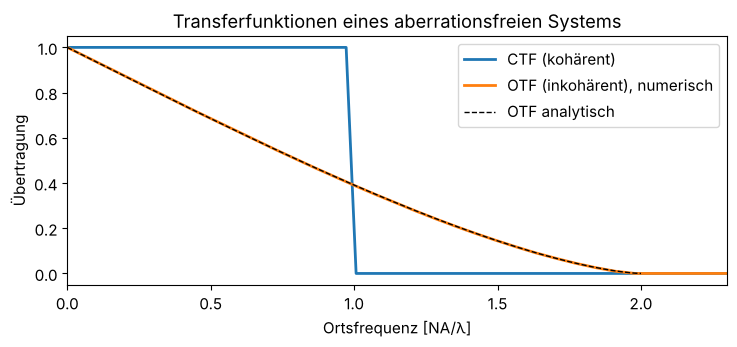

In [7]:
fx, fy = freq_grid(x, y, wavenumbers=False, normal_order=True)
CTF = (np.hypot(fx, fy) <= NA/wl).astype(float)
OTF = np.abs(H_inc)/np.abs(H_inc).max()
f_axis = fx[N//2]
nu = np.linspace(0, 1, 200)
otf_ana = 2/np.pi*(np.arccos(nu) - nu*np.sqrt(1 - nu**2))
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(f_axis*wl/NA, CTF[N//2], lw=2, label="CTF (kohärent)")
ax.plot(f_axis*wl/NA, OTF[N//2], lw=2, label="OTF (inkohärent), numerisch")
ax.plot(2*nu, otf_ana, "k--", lw=1, label="OTF analytisch")
ax.set_xlim(0, 2.3); ax.set_xlabel("Ortsfrequenz [NA/λ]"); ax.set_ylabel("Übertragung")
ax.legend(); ax.set_title("Transferfunktionen eines aberrationsfreien Systems")
fig.tight_layout()

## 5. Zwei Punkte: Rayleigh-Kriterium

Zwei inkohärente Punktquellen im Abstand $0.61\,\lambda/\mathrm{NA}$ (Maximum der
einen PSF auf der ersten Nullstelle der anderen) sind gerade noch getrennt, mit
einer Einsattelung auf etwa 73 %. Bei **kohärenter** Beleuchtung entscheidet die
relative Phase: Gleichphasige Punkte verschmelzen, gegenphasige sind durch eine
dunkle Linie klar getrennt (das Prinzip der Phasenschiebemasken in der Lithographie).

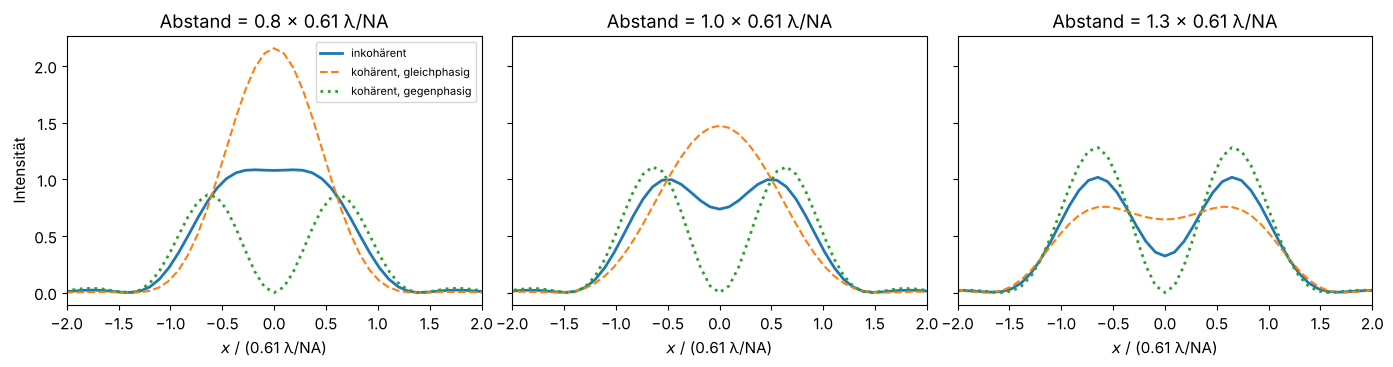

In [8]:
d_R = 0.61*wl/NA
KX, KY = freq_grid(x, y, wavenumbers=True, normal_order=True)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, sep in zip(axes, (0.8*d_R, d_R, 1.3*d_R)):
    shift = lambda f, dx: inv_FT(FT(f)*np.exp(-1j*KX*dx))  # Verschiebung um dx per Fourier-Shift
    h1, h2 = shift(h, -sep/2), shift(h, +sep/2)
    norm = np.abs(h).max()**2
    ax.plot(x/d_R, (np.abs(h1)**2 + np.abs(h2)**2)[N//2]/norm, lw=2, label="inkohärent")
    ax.plot(x/d_R, np.abs(h1 + h2)[N//2]**2/norm, "--", label="kohärent, gleichphasig")
    ax.plot(x/d_R, np.abs(h1 - h2)[N//2]**2/norm, ":", lw=2, label="kohärent, gegenphasig")
    ax.set_xlim(-2, 2); ax.set_xlabel("$x$ / (0.61 λ/NA)")
    ax.set_title(f"Abstand = {sep/d_R:.1f} × 0.61 λ/NA")
axes[0].set_ylabel("Intensität"); axes[0].legend(fontsize=8)
fig.tight_layout()

## 6. Der Fokus in drei Dimensionen

Das Feld in der Fokusebene ist die (Amplituden-)PSF $h$. Propagiert man es mit
dem exakten Rayleigh-Sommerfeld-Propagator nach vorn und hinten, erhält man die
dreidimensionale PSF. Für kleine NA gilt auf der Achse

$$I(0, 0, z) = I_0\,\mathrm{sinc}^2\!\left(\frac{\mathrm{NA}^2 z}{2\lambda}\right),
  \qquad \mathrm{sinc}(x) = \frac{\sin \pi x}{\pi x},$$

mit der ersten Nullstelle bei $z = 2\lambda/\mathrm{NA}^2$. Bei großer NA ist der
Fokus kürzer als die paraxiale Formel vorhersagt, weil die Randstrahlen
steiler einfallen.

**Vorsicht beim Rückwärtspropagieren:** Für $z < 0$ werden evaneszente
Komponenten mit $e^{+|k_z||z|}$ *verstärkt*. Schon Rundungsfehler von $10^{-16}$
in diesem Frequenzbereich wachsen dann über alle Grenzen. Abhilfe schafft
Zeitumkehr: $U(-z) = \overline{\mathcal{P}_z\big[\overline{U}\big]}$. Für
propagierende Wellen ist das exakt die Rückpropagation, evaneszente werden
dabei gedämpft statt verstärkt.

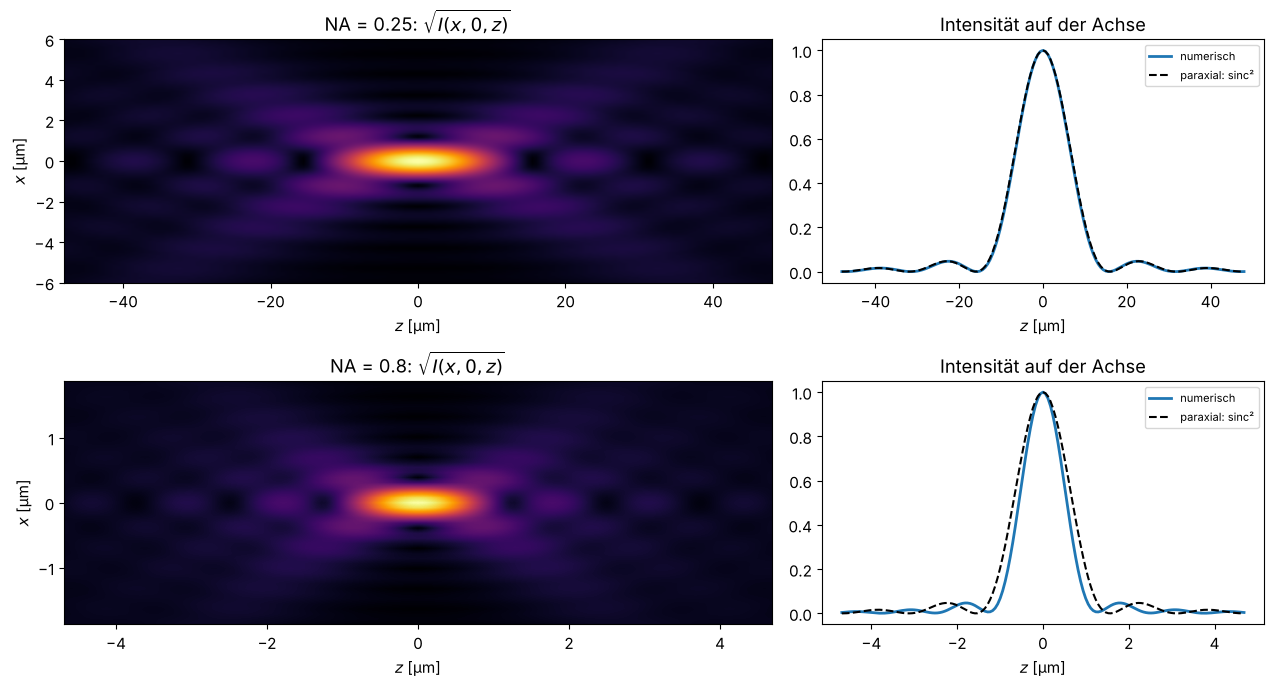

In [9]:
L3, N3 = 40.0, 512  # Fenster groß genug für den defokussierten Lichtkegel
x3, y3, _, _ = grid2d(-L3/2, L3/2, -L3/2, L3/2, N3)
fig, axes = plt.subplots(2, 2, figsize=(13, 7), gridspec_kw={"width_ratios": [1.6, 1]})
for row, NA3 in enumerate((0.25, 0.8)):
    h3 = imaging.get_psf(x3, y3, NA3, k)
    z_max = 3*2*wl/NA3**2
    z3 = np.linspace(-z_max, z_max, 161)
    def propagate(U, z):
        if z >= 0:
            return prop.rayleigh_sommerfeld_I_TF(U, x3, y3, z, wl)[0]
        return np.conj(prop.rayleigh_sommerfeld_I_TF(np.conj(U), x3, y3, -z, wl)[0])  # Zeitumkehr
    stack = np.array([propagate(h3, z)[N3//2] for z in z3])
    I3 = np.abs(stack)**2
    I3 /= I3.max()
    axes[row, 0].imshow(I3.T**0.5, extent=(z3[0], z3[-1], x3[0], x3[-1]), aspect="auto", cmap="inferno",
                        interpolation="bilinear")
    axes[row, 0].set_ylim(-3*wl/NA3, 3*wl/NA3)
    axes[row, 0].set_xlabel("$z$ [µm]"); axes[row, 0].set_ylabel("$x$ [µm]")
    axes[row, 0].set_title(f"NA = {NA3}: $\\sqrt{{I(x, 0, z)}}$")
    axes[row, 1].plot(z3, I3[:, N3//2], lw=2, label="numerisch")
    axes[row, 1].plot(z3, np.sinc(NA3**2*z3/(2*wl))**2, "k--", label="paraxial: sinc²")
    axes[row, 1].set_xlabel("$z$ [µm]"); axes[row, 1].set_title("Intensität auf der Achse"); axes[row, 1].legend(fontsize=8)
fig.tight_layout()